# 10 - Naive Bayes

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate a Gaussian Naive Bayes model on the processed PhiUSIIL data, compare different feature sets, choose a better cut-off and find out which features the model relies on (Experiment 1), and train and test a URL-only version on both datasets (Experiment 2).

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.naive_bayes import GaussianNB

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, get_feature_sets, load_feature_groups, load_train_test, load_url_experiment, sample_rows
from src.features import extract_url_features
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_by_source,
    cross_validate_model,
    evaluate_model,
    evaluate_predictions,
    fit_with_weights,
    get_scores,
    make_cv,
    make_sample_weights,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
    to_file_name,
    tune_by_source,
    tune_cutoff_by_source,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

Gaussian Naive Bayes uses Bayes' theorem. For each URL, it asks: "Given these feature values, is phishing or legitimate more likely?" To keep the maths simple, it makes two assumptions:

1. **Every feature follows a bell curve (normal distribution)** inside each class.
2. **The features are independent** of each other once we know the class. This is the "naive" part.

Our EDA found that 26 of the 31 continuous features are highly skewed, so we use `make_scaled_pipeline`. It applies a log transform (`log1p`), which makes skewed features closer to a bell curve, and then scales them. Both steps are fitted only on the training data, inside the pipeline.

Naive Bayes has only one setting to tune: `var_smoothing`. It adds a small amount to the variance of every feature, so that a feature with almost no spread cannot dominate the prediction. We try values from 10⁻¹² to 10⁻².

Naive Bayes trains in seconds, so we use the full training set for tuning (`TUNING_SAMPLE_SIZE = None`).

In [3]:
MODEL_NAME = "Naive Bayes"
model = make_scaled_pipeline(GaussianNB())

param_grid = {
    "gaussiannb__var_smoothing": np.logspace(-12, -2, 6),
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each value in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'gaussiannb__var_smoothing': np.float64(1e-12)}
Best cross-validation F1: 0.9997


In [5]:
tuning_table = pd.DataFrame({
    "var_smoothing": [f"{v:.0e}" for v in search.cv_results_["param_gaussiannb__var_smoothing"]],
    "Mean F1": search.cv_results_["mean_test_score"],
    "Std": search.cv_results_["std_test_score"],
})
tuning_table.round(4)

,var_smoothing,Mean F1,Std
0,1e-12,0.9997,0.0001
1,1e-10,0.9996,0.0002
2,1e-08,0.9995,0.0002
3,1e-06,0.9994,0.0001
4,1e-04,0.9992,0.0001
5,1e-02,0.9987,0.0002


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [6]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9997,0.0001
Precision,0.9995,0.0003
Recall,0.9999,0.0001
F1,0.9997,0.0002
ROC-AUC,0.9999,0.0001


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [7]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.4 seconds


,Test Score
Accuracy,0.9997
Precision,0.9994
Recall,0.9999
F1,0.9996
ROC-AUC,0.9998


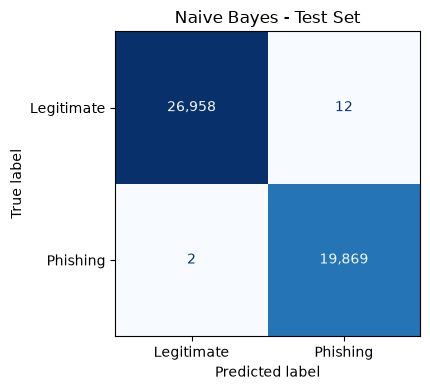

In [8]:
test_pred = final_model.predict(X_test)
plot_confusion_matrix(y_test, test_pred, f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9997,0.9994,0.9999,0.9996,0.9998
Original features only,0.9995,0.9989,0.9999,0.9994,0.9997
Without URLSimilarityIndex,0.9957,0.9993,0.9904,0.9949,0.9998


## 5. Choosing the Cut-off

By default, a URL is called phishing when the model gives it a probability of 0.5 or more. But the two mistakes do not cost the same: **a missed phishing URL can steal a user's password, while a false alarm only blocks a safe page**. So we choose the cut-off based on the cost of errors.

Our rule: **find at least 95% of phishing URLs (recall ≥ 0.95), and among the cut-offs that do this, pick the one with the fewest false alarms (highest precision).**

To choose the cut-off without touching the test set, we use *out-of-fold* predictions: with 5-fold cross-validation, every training URL gets a probability from a model that did not see it during training. We then apply the chosen cut-off to the test set once.

This step is especially useful for Naive Bayes, because its independence assumption pushes most probabilities very close to 0 or 1, so 0.5 is not always a good place to cut.

In [10]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=make_cv(5), method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

TARGET_RECALL = 0.95
meets_target = recall[:-1] >= TARGET_RECALL
best_threshold = thresholds[meets_target][np.argmax(precision[:-1][meets_target])]
print(f"Chosen cut-off: {best_threshold:.4f}")

Chosen cut-off: 1.0000


In [11]:
test_proba = final_model.predict_proba(X_test)[:, 1]
tuned_pred = (test_proba >= best_threshold).astype(int)
tuned_results = evaluate_predictions(y_test, tuned_pred, test_proba)

pd.DataFrame({
    "Cut-off 0.5": test_results,
    f"Cut-off {best_threshold:.4f}": tuned_results,
}).round(4)

,Cut-off 0.5,Cut-off 1.0000
Accuracy,0.9997,0.9998
Precision,0.9994,0.9995
Recall,0.9999,0.9999
F1,0.9996,0.9997
ROC-AUC,0.9998,0.9998


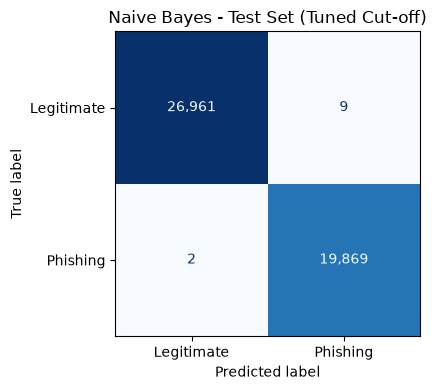

In [12]:
plot_confusion_matrix(y_test, tuned_pred, f"{MODEL_NAME} - Test Set (Tuned Cut-off)")

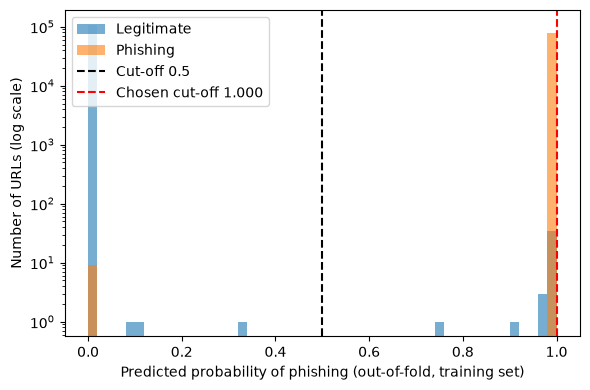

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(oof_proba[y_train == 0], bins=50, alpha=0.6, label="Legitimate", log=True)
ax.hist(oof_proba[y_train == 1], bins=50, alpha=0.6, label="Phishing", log=True)
ax.axvline(0.5, color="black", linestyle="--", label="Cut-off 0.5")
ax.axvline(best_threshold, color="red", linestyle="--", label=f"Chosen cut-off {best_threshold:.3f}")
ax.set_xlabel("Predicted probability of phishing (out-of-fold, training set)")
ax.set_ylabel("Number of URLs (log scale)")
ax.legend()
fig.tight_layout()
plt.show()

**What this shows:** Naive Bayes is extremely over-confident. Almost every phishing URL in the training set (99.99%) gets a probability of exactly 1.0, so the histogram has almost nothing in the middle. Because of this, the rule picks a cut-off of 1.0, which means "only call a URL phishing when the model is completely sure". On the test set this removes 3 false alarms (12 → 9) and misses no extra phishing URLs (still 2). That is 3 URLs out of 46,841, which is too small to be a meaningful difference, and a cut-off of exactly 1.0 is fragile. So we keep **0.5 as the main result** for this model and report the tuned cut-off only as an extra.

## 6. Prediction Speed

A phishing detector must be fast, because it checks every link a user opens. We measure how long the model takes to classify all test URLs.

In [14]:
start = time.perf_counter()
final_model.predict(X_test)
predict_time = time.perf_counter() - start

print(f"Training time:   {train_time:.2f} seconds")
print(f"Prediction time: {predict_time:.3f} seconds for {len(X_test):,} URLs "
      f"({predict_time / len(X_test) * 1e6:.1f} microseconds per URL)")

Training time:   0.44 seconds
Prediction time: 0.092 seconds for 46,841 URLs (2.0 microseconds per URL)


## 7. Which Features Does the Model Rely On?

Naive Bayes does not give feature importances directly, so we use **permutation importance**: we shuffle one feature at a time on the test set and see how much ROC-AUC drops. If the score drops a lot, the model was relying on that feature. We use a sample of 10,000 test URLs and repeat each shuffle 3 times.

Many of our features are correlated, so shuffling one feature can look harmless because a "twin" feature still carries the same information. To handle this, we also shuffle **whole groups** of features at once.

In [15]:
get_score = get_scores

def permutation_auc_drop(model, X, y, groups, repeats=3):
    rng = np.random.default_rng(RANDOM_STATE)
    base = roc_auc_score(y, get_score(model, X))
    rows = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(repeats):
            X_shuffled = X.copy()
            X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]
            drops.append(base - roc_auc_score(y, get_score(model, X_shuffled)))
        rows[name] = {"AUC drop": np.mean(drops), "Std": np.std(drops)}
    return pd.DataFrame(rows).T.sort_values("AUC drop", ascending=False)

X_imp, y_imp = sample_rows(X_test, y_test, 10000)

start = time.perf_counter()
single_importance = permutation_auc_drop(final_model, X_imp, y_imp, {col: [col] for col in X_imp.columns})
print(f"Done in {time.perf_counter() - start:.0f} seconds")
single_importance.head(15).round(4)

Done in 5 seconds


,AUC drop,Std
URLSimilarityIndex,0.2121,0.0007
NoOfSlashesInURL,0.1248,0.0015
PathLength,0.1243,0.0018
IsHTTPS,0.1084,0.0019
PathDepth,0.0563,0.0003
QueryLength,0.0126,0.0006
NoOfQMarkInURL,0.0124,0.0002
HasTitle,0.0121,0.0009
NoOfEqualsInURL,0.0109,0.0004
HasAtSymbol,0.0026,0.0001


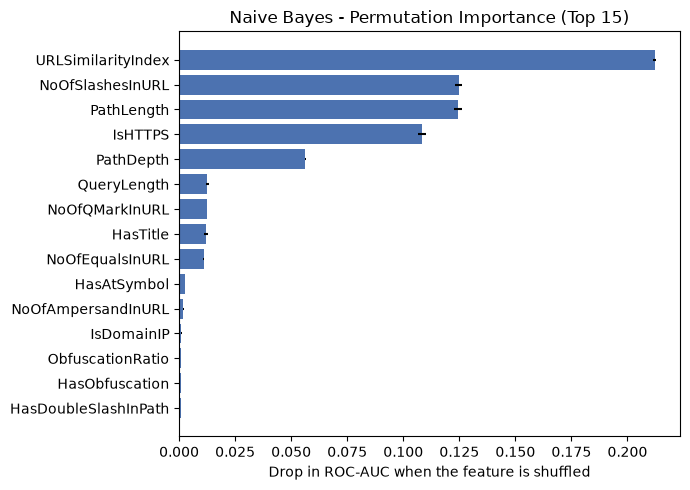

In [16]:
save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)

top = single_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["AUC drop"], xerr=top["Std"], color="#4C72B0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"{MODEL_NAME} - Permutation Importance (Top 15)")
fig.tight_layout()
fig.savefig(save_dir / f"{to_file_name(MODEL_NAME)}.png", dpi=300)
plt.show()

In [17]:
groups = load_feature_groups()
group_importance = permutation_auc_drop(final_model, X_imp, y_imp, {
    "URLSimilarityIndex": ["URLSimilarityIndex"],
    "Other original features (47)": [col for col in groups["original"] if col != "URLSimilarityIndex"],
    "Engineered features (21)": groups["engineered"],
})
group_importance.round(4)

,AUC drop,Std
URLSimilarityIndex,0.2135,0.0024
Other original features (47),0.1477,0.0021
Engineered features (21),0.1256,0.0011


## 8. Where Does the Model Go Wrong?

A score tells us how often the model is wrong, but not why. Here we look at the URLs the model got wrong at the default cut-off (0.5).

In [18]:
test_urls = pd.read_csv(PROCESSED_DIR / "test_urls.csv")["URL"].values
errors = pd.DataFrame({"URL": test_urls, "Actual": y_test.values, "Predicted": test_pred})

missed = errors[(errors["Actual"] == 1) & (errors["Predicted"] == 0)]
false_alarms = errors[(errors["Actual"] == 0) & (errors["Predicted"] == 1)]
print(f"Missed phishing URLs (false negatives): {len(missed):,}")
print(f"False alarms (false positives):         {len(false_alarms):,}")

Missed phishing URLs (false negatives): 2
False alarms (false positives):         12


In [19]:
print("Examples of missed phishing URLs:")
display(missed.sample(min(10, len(missed)), random_state=RANDOM_STATE)[["URL"]])
print("Examples of false alarms:")
display(false_alarms.sample(min(10, len(false_alarms)), random_state=RANDOM_STATE)[["URL"]])

Examples of missed phishing URLs:


,URL
4218,https://midgleyspublichouse.com
3381,https://www.wsend.co


Examples of false alarms:


,URL
34903,https://www.wiskuu.nl
31027,https://www.lewiscarrollcentre.org.uk
45,https://www.counterpointpress.com
24910,https://www.vocaleapp.com
10392,https://www.oppaga.fl.gov
4383,https://www.bauermedia.co.uk
1378,https://www.calafco.org
36645,https://www.britisharmedforces.org
8614,https://www.1920-30.com
16291,https://www.guizot.com


In [20]:
def url_shape(urls):
    urls = pd.Series(urls)
    return pd.Series({
        "Avg URL length": urls.str.len().mean(),
        "Has a path (%)": urls.str.replace(r"^https?://", "", regex=True).str.contains("/.", regex=True).mean() * 100,
        "Uses HTTPS (%)": urls.str.startswith("https").mean() * 100,
    })

pd.DataFrame({
    "All phishing": url_shape(errors.loc[errors["Actual"] == 1, "URL"]),
    "Missed phishing": url_shape(missed["URL"]),
    "All legitimate": url_shape(errors.loc[errors["Actual"] == 0, "URL"]),
    "False alarms": url_shape(false_alarms["URL"]),
}).round(1)

,All phishing,Missed phishing,All legitimate,False alarms
Avg URL length,46.1,25.5,27.2,27.2
Has a path (%),28.2,0.0,0.0,0.0
Uses HTTPS (%),48.7,100.0,100.0,100.0


## 9. Experiment 2: URL Features Only

In real use, DetectIt only gets a URL, not the HTML of the page. So here the model only uses the **40 URL features** that we can create from any URL (18 from `02_preprocessing.ipynb` and 22 new ones from `03_external_dataset.ipynb`).

In the first version of this experiment, we trained only on PhiUSIIL, and every model scored about 50% on the Kaggle dataset, because the legitimate URLs in the two datasets look very different. Now we train on **both datasets**:

- **Training set:** PhiUSIIL training set (80%) + Kaggle training part (80%)
- **Test sets:** PhiUSIIL test set (20%) and Kaggle test part (20%). We test on them **separately**. The PhiUSIIL test set is about 21 times bigger, so one combined score would mostly show the PhiUSIIL score and hide how the model does on Kaggle URLs.

No URL is in both a training set and a test set (checked in `02_preprocessing.ipynb` and `03_external_dataset.ipynb`).

In [21]:
X_url_train, y_url_train, url_source, url_test_sets = load_url_experiment()

print(f"Training set: {X_url_train.shape[0]:,} rows | {X_url_train.shape[1]} features")
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    print(f"{test_name}: {X_url_test.shape[0]:,} rows")

Training set: 196,230 rows | 40 features
PhiUSIIL test set: 46,841 rows
Kaggle test set: 2,217 rows


### Sample Weights

The training set has about 21 times more PhiUSIIL URLs than Kaggle URLs. Without help, the model would mostly learn PhiUSIIL patterns and almost ignore the Kaggle URLs. So we give each Kaggle URL a bigger **sample weight**. For Naive Bayes, a weight of 21 means one Kaggle URL counts like 21 URLs when the model calculates the share of each class and the mean and spread of each feature, so both datasets matter equally during training.

In [22]:
url_weights = make_sample_weights(url_source)

pd.DataFrame({
    "Training URLs": url_source.value_counts(),
    "Weight per URL": pd.Series(url_weights, index=url_source).groupby(level=0).first(),
}).round(2)

,Training URLs,Weight per URL
Source,,
Kaggle,8867,21.13
PhiUSIIL,187363,1.00


### Hyperparameter Tuning

The best `var_smoothing` from Section 1 was chosen for 69 features on PhiUSIIL only. Experiment 2 uses different features and more varied data, so we tune again. For every value, we run 3-fold cross-validation on the training set (with sample weights) and calculate the F1-score separately for PhiUSIIL URLs and Kaggle URLs. We keep the value with the highest **average of the two F1-scores**, so the model works well on both datasets, not just on the bigger one. The test sets are not used here.

We try a wider range than in Section 1 (10⁻¹² up to 1), because a first run with the Section 1 values picked the largest value (10⁻²), which means the best value could be even larger. Naive Bayes is fast, so we tune on the full training set.

In [23]:
url_param_grid = {
    "gaussiannb__var_smoothing": np.logspace(-12, 0, 13),
}

X_url_tune, y_url_tune, url_source_tune = sample_rows(X_url_train, y_url_train, TUNING_SAMPLE_SIZE, groups=url_source)

url_tuning, url_best_params = tune_by_source(model, url_param_grid, X_url_tune, y_url_tune, url_source_tune)
url_best_model = clone(model).set_params(**url_best_params)

print(f"Best settings: {url_best_params}")
url_tuning.assign(gaussiannb__var_smoothing=url_tuning["gaussiannb__var_smoothing"].map(lambda v: f"{v:.0e}")).round(4)

Best settings: {'gaussiannb__var_smoothing': np.float64(0.01)}


,gaussiannb__var_smoothing,PhiUSIIL F1,Kaggle F1,Mean F1
0,1e-02,0.6116,0.7242,0.6679
1,1e-03,0.5956,0.7132,0.6544
2,1e-01,0.5799,0.7169,0.6484
3,1e-04,0.5709,0.6993,0.6351
4,1e-05,0.5444,0.6871,0.6158
5,1e-06,0.5255,0.6756,0.6005
6,1e-07,0.5061,0.6658,0.5859
7,1e-08,0.4904,0.6554,0.5729
8,1e-09,0.4747,0.6433,0.5590
9,1e-10,0.4567,0.6330,0.5449


### Cross-Validation

We check the best setting with 5-fold cross-validation and calculate the scores for PhiUSIIL URLs and Kaggle URLs separately. The Kaggle scores here are used to choose the best model for Experiment 2. The test sets are only used to report the final scores.

In [24]:
url_cv_results = cross_validate_by_source(url_best_model, X_url_tune, y_url_tune, url_source_tune)
url_cv_results.round(4)

,PhiUSIIL Mean,PhiUSIIL Std,Kaggle Mean,Kaggle Std
Accuracy,0.7607,0.0021,0.7564,0.0109
Precision,0.9804,0.0040,0.8229,0.0088
Recall,0.4447,0.0054,0.6479,0.0257
F1,0.6119,0.0049,0.7248,0.0167
ROC-AUC,0.9142,0.0013,0.8385,0.0028


### Final Test

We train two models with the best setting and test both of them on both test sets:

- **Trained on PhiUSIIL only:** the first version of this experiment, with the 40 URL features.
- **Trained on both datasets:** the new version, with sample weights.

Comparing the two shows how much adding Kaggle URLs to the training set helps.

In [25]:
phiusiil_only = (url_source == "PhiUSIIL").to_numpy()

start = time.perf_counter()
url_model = fit_with_weights(clone(url_best_model), X_url_train, y_url_train, url_weights)
url_train_time = time.perf_counter() - start

url_models = {
    "Trained on PhiUSIIL only": clone(url_best_model).fit(X_url_train[phiusiil_only], y_url_train[phiusiil_only]),
    "Trained on both datasets": url_model,
}

url_results = {}
for train_name, model_version in url_models.items():
    for test_name, (X_url_test, y_url_test) in url_test_sets.items():
        url_results[(train_name, test_name)] = evaluate_model(model_version, X_url_test, y_url_test)

print(f"Training time (both datasets): {url_train_time:.1f} seconds")
pd.DataFrame(url_results).T.round(4)

Training time (both datasets): 0.3 seconds


Accuracy  Precision  Recall  \
Trained on PhiUSIIL only PhiUSIIL test set    0.9880     0.9769  0.9953   
                         Kaggle test set      0.4957     0.4957  0.9991   
Trained on both datasets PhiUSIIL test set    0.7633     0.9804  0.4511   
                         Kaggle test set      0.7483     0.8271  0.6224   

                                                F1  ROC-AUC  
Trained on PhiUSIIL only PhiUSIIL test set  0.9860   0.9952  
                         Kaggle test set    0.6626   0.5000  
Trained on both datasets PhiUSIIL test set  0.6179   0.9170  
                         Kaggle test set    0.7103   0.8259

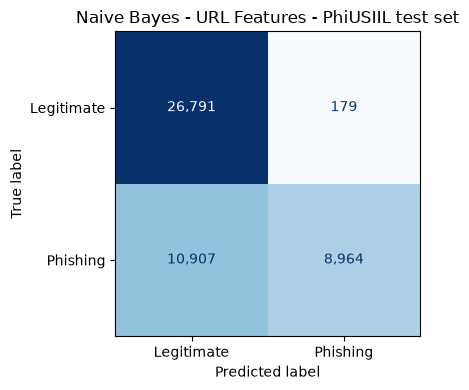

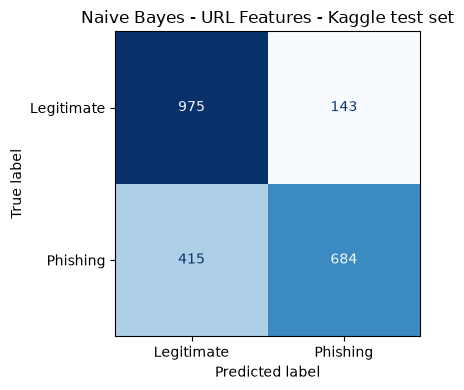

In [26]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    plot_confusion_matrix(y_url_test, url_model.predict(X_url_test), f"{MODEL_NAME} - URL Features - {test_name}")

### Choosing the Cut-off

The sample weights make Kaggle URLs count much more during training, which moves the probabilities, so 0.5 may not be the best place to cut for both datasets.

We choose the cut-off without touching the test sets. With 5-fold cross-validation, every training URL gets a probability from a model that did not see it during training (*out-of-fold* predictions). For each cut-off from 0.05 to 0.95, we calculate the F1-score for PhiUSIIL URLs and Kaggle URLs, and keep the cut-off with the highest average. We then apply it to the test sets once.

In [27]:
cutoff_table, best_cutoff = tune_cutoff_by_source(url_best_model, X_url_train, y_url_train, url_source)

print(f"Best cut-off: {best_cutoff:.2f}")
cutoff_table.round(4)

Best cut-off: 0.05


,Cut-off,PhiUSIIL F1,Kaggle F1,Mean F1
0,0.05,0.6302,0.7311,0.6806
1,0.10,0.6249,0.7308,0.6778
2,0.15,0.6218,0.7294,0.6756
3,0.20,0.6197,0.7283,0.6740
4,0.25,0.6177,0.7270,0.6724
5,0.30,0.6164,0.7265,0.6714
6,0.35,0.6153,0.7269,0.6711
7,0.40,0.6141,0.7261,0.6701
8,0.45,0.6129,0.7255,0.6692
9,0.50,0.6119,0.7250,0.6684


In [28]:
cutoff_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_scores = get_scores(url_model, X_url_test)
    cutoff_results[("Cut-off 0.5", test_name)] = url_results[("Trained on both datasets", test_name)]
    cutoff_results[(f"Cut-off {best_cutoff:.2f}", test_name)] = evaluate_predictions(y_url_test, (url_scores >= best_cutoff).astype(int), url_scores)

pd.DataFrame(cutoff_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
Cut-off 0.5,PhiUSIIL test set,0.7633,0.9804,0.4511,0.6179,0.9170
Cut-off 0.05,PhiUSIIL test set,0.7714,0.9737,0.4739,0.6375,0.9170
Cut-off 0.5,Kaggle test set,0.7483,0.8271,0.6224,0.7103,0.8259
Cut-off 0.05,Kaggle test set,0.7546,0.8157,0.6524,0.7250,0.8259


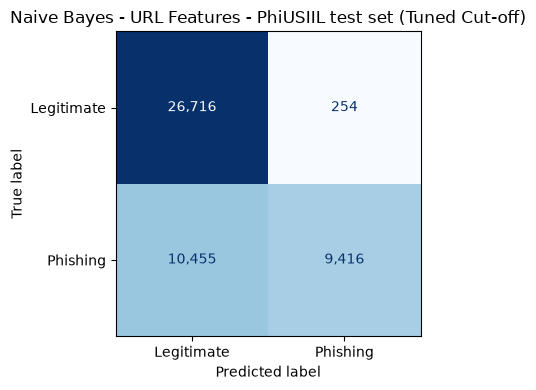

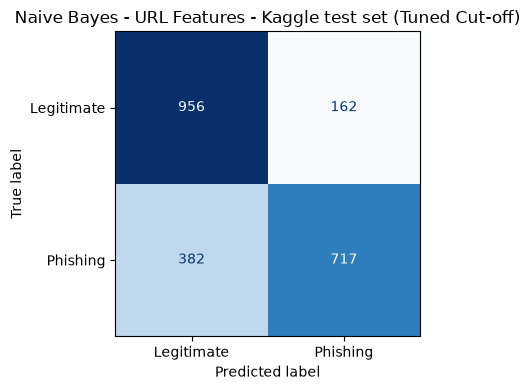

In [29]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_tuned_pred = (get_scores(url_model, X_url_test) >= best_cutoff).astype(int)
    plot_confusion_matrix(y_url_test, url_tuned_pred, f"{MODEL_NAME} - URL Features - {test_name} (Tuned Cut-off)")

### Did the 22 New URL Features Help?

We train the same model on both datasets again, but only with the 18 URL features from `02_preprocessing.ipynb`, and compare it with the model that uses all 40 URL features.

In [30]:
base_url_features = list(extract_url_features("example.com"))
base_url_model = fit_with_weights(clone(url_best_model), X_url_train[base_url_features], y_url_train, url_weights)

url_feature_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_feature_results[("18 URL features", test_name)] = evaluate_model(base_url_model, X_url_test[base_url_features], y_url_test)
    url_feature_results[("40 URL features", test_name)] = url_results[("Trained on both datasets", test_name)]

pd.DataFrame(url_feature_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
18 URL features,PhiUSIIL test set,0.7432,0.9533,0.4149,0.5781,0.9126
40 URL features,PhiUSIIL test set,0.7633,0.9804,0.4511,0.6179,0.9170
18 URL features,Kaggle test set,0.7379,0.8669,0.5569,0.6781,0.8308
40 URL features,Kaggle test set,0.7483,0.8271,0.6224,0.7103,0.8259


### Does the Model Depend on `www` and HTTPS?

In PhiUSIIL, every legitimate URL starts with `www` and uses HTTPS. So a model may learn that a URL without `www` or HTTPS is suspicious, and a legitimate website without them might get a false alarm.

To check how much the model depends on this, we remove `http://`, `https://` and `www.` from every URL before creating the features. This removes `HasWWW` and `HasHTTPSScheme`, and also removes this information from the other features (for example, `FullURLLength` no longer counts `https://www.`). We then train the same model with the same settings on both datasets and compare the scores.

In [31]:
X_clean_train, _, _, clean_test_sets = load_url_experiment(clean_urls=True)
clean_model = fit_with_weights(clone(url_best_model), X_clean_train, y_url_train, url_weights)

clean_results = {}
for test_name, (X_clean_test, y_clean_test) in clean_test_sets.items():
    clean_results[("With www and HTTPS", test_name)] = url_results[("Trained on both datasets", test_name)]
    clean_results[("Without www and HTTPS", test_name)] = evaluate_model(clean_model, X_clean_test, y_clean_test)

print(f"Features without www and HTTPS: {X_clean_train.shape[1]}")
pd.DataFrame(clean_results).T.round(4)

Features without www and HTTPS: 38


,,Accuracy,Precision,Recall,F1,ROC-AUC
With www and HTTPS,PhiUSIIL test set,0.7633,0.9804,0.4511,0.6179,0.9170
Without www and HTTPS,PhiUSIIL test set,0.7650,0.9731,0.4588,0.6236,0.8727
With www and HTTPS,Kaggle test set,0.7483,0.8271,0.6224,0.7103,0.8259
Without www and HTTPS,Kaggle test set,0.7447,0.8286,0.6115,0.7037,0.8097


## 10. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [32]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time, "Predict Time (s)": predict_time},
    {"Experiment": f"Test set - Tuned cut-off ({best_threshold:.4f})", **tuned_results},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - Cross-validation - PhiUSIIL", **url_cv_results["PhiUSIIL Mean"].to_dict()},
    {"Experiment": "URL features - Cross-validation - Kaggle", **url_cv_results["Kaggle Mean"].to_dict()},
]

for (train_name, test_name), scores in url_results.items():
    row = {"Experiment": f"URL features - {train_name} - {test_name}", **scores}
    if train_name == "Trained on both datasets" and test_name == "PhiUSIIL test set":
        row["Train Time (s)"] = url_train_time
    results.append(row)

for (feature_name, test_name), scores in url_feature_results.items():
    if feature_name == "18 URL features":
        results.append({"Experiment": f"URL features - Trained on both datasets (18 URL features) - {test_name}", **scores})

for (version, test_name), scores in clean_results.items():
    if version == "Without www and HTTPS":
        results.append({"Experiment": f"URL features - Trained on both datasets (without www and HTTPS) - {test_name}", **scores})

for (version, test_name), scores in cutoff_results.items():
    if version != "Cut-off 0.5":
        results.append({"Experiment": f"URL features - Trained on both datasets (cut-off {best_cutoff:.2f}) - {test_name}", **scores})

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Predict Time (s)
0,Naive Bayes,Cross-validation,0.9997,0.9995,0.9999,0.9997,0.9999,NaN,NaN
1,Naive Bayes,Test set - All features,0.9997,0.9994,0.9999,0.9996,0.9998,0.4393,0.0916
2,Naive Bayes,Test set - Tuned cut-off (1.0000),0.9998,0.9995,0.9999,0.9997,0.9998,NaN,NaN
3,Naive Bayes,Test set - Original features only,0.9995,0.9989,0.9999,0.9994,0.9997,NaN,NaN
4,Naive Bayes,Test set - Without URLSimilarityIndex,0.9957,0.9993,0.9904,0.9949,0.9998,NaN,NaN
5,Naive Bayes,URL features - Cross-validation - PhiUSIIL,0.7607,0.9804,0.4447,0.6119,0.9142,NaN,NaN
6,Naive Bayes,URL features - Cross-validation - Kaggle,0.7564,0.8229,0.6479,0.7248,0.8385,NaN,NaN
7,Naive Bayes,URL features - Trained on PhiUSIIL only - PhiU...,0.9880,0.9769,0.9953,0.9860,0.9952,NaN,NaN
8,Naive Bayes,URL features - Trained on PhiUSIIL only - Kagg...,0.4957,0.4957,0.9991,0.6626,0.5000,NaN,NaN
9,Naive Bayes,URL features - Trained on both datasets - PhiU...,0.7633,0.9804,0.4511,0.6179,0.9170,0.3290,NaN


## 11. Findings

**1. Very high scores on the PhiUSIIL test set.** Naive Bayes reaches 99.97% accuracy, an F1-score of 0.9996 and a ROC-AUC of 0.9998. It missed only **2 of 19,871** phishing URLs and wrongly flagged **12 of 26,970** legitimate URLs. The cross-validation F1 (0.9997 ± 0.0002) is almost the same as the test F1, so the cross-validation estimate was honest and the model is not overfitting.

**2. Tuning barely mattered.** All `var_smoothing` values gave an F1 between 0.9987 and 0.9997. The smallest value (10⁻¹²) was best, but the differences are tiny.

**3. Very fast.** Training took about 0.4 seconds and predicting 46,841 URLs about 0.09 seconds (about 2 microseconds per URL). This makes Naive Bayes a good choice for real-time checking. (Times depend on the computer used.)

**4. The new features helped only a little.** With original features only, F1 was 0.9994. With our engineered features, it was 0.9996. The gap is too small to claim a meaningful improvement.

**5. `URLSimilarityIndex` matters most, but the model still works without it.** Without this feature, recall drops from 0.9999 to 0.990 (188 more phishing URLs missed), while precision stays at 0.999. ROC-AUC is still 0.9998, so the model still *ranks* URLs well, but the 0.5 cut-off no longer fits as well. Permutation importance agrees: shuffling `URLSimilarityIndex` lowers ROC-AUC by 0.21, followed by `NoOfSlashesInURL` (0.12), `PathLength` (0.12), `IsHTTPS` (0.11) and `PathDepth` (0.06). These show which features the model *relies on*, not what *causes* a URL to be phishing.

**6. The mistakes reveal how the dataset was built.** In the PhiUSIIL test set, **every legitimate URL is a plain HTTPS home page** (0% have a path, 100% use HTTPS), while 28.2% of phishing URLs have a path and only 48.7% use HTTPS. The 2 missed phishing URLs and all 12 false alarms are plain HTTPS home pages, so the model only fails where a phishing URL looks exactly like a typical legitimate URL in this dataset. This also means the near-perfect scores partly reflect how PhiUSIIL was collected, which we test in Experiment 2 (Section 9).

**7. Choosing a cut-off did not change the result.** Naive Bayes gives almost every phishing URL a probability of exactly 1.0. The tuned cut-off (1.0) removed 3 false alarms, which is not a meaningful difference, so we report the 0.5 cut-off as the main result.

**Limitation:** Naive Bayes assumes that features are independent, but many of our features are correlated (for example, `NoOfSlashesInURL`, `PathLength` and `PathDepth` all describe the URL path). This is the reason for its over-confident probabilities. It still works well here because a few features separate the classes so clearly.

### Experiment 2: URL Features Only

**1. Training on both datasets fixed the Kaggle collapse, but it hurt the PhiUSIIL score.** When trained on PhiUSIIL only, the model scored 98.8% on the PhiUSIIL test set (F1 0.986), but only **49.6% on the Kaggle test set** with a ROC-AUC of 0.500. It called 1,117 of the 1,118 legitimate Kaggle URLs phishing. After adding the Kaggle training part with sample weights, it scored **74.8% on the Kaggle test set** (F1 0.710, ROC-AUC 0.826), but only **76.3% on the PhiUSIIL test set** (F1 0.618), because it missed 10,907 of 19,871 PhiUSIIL phishing URLs (recall 45.1%). Its precision on PhiUSIIL stayed high (98.0%, only 179 false alarms).

**2. Kaggle test set mistakes:** 143 false alarms (out of 1,118 legitimate URLs) and 415 missed phishing URLs (out of 1,099).

**3. Why Naive Bayes struggles here.** Gaussian Naive Bayes keeps **one bell curve per feature for each class**. In Experiment 2, the legitimate class contains two very different groups: PhiUSIIL legitimate URLs are short `https://www.` home pages, while 63.5% of Kaggle legitimate URLs have a path and only 43% use HTTPS. One bell curve cannot describe both groups, so it becomes very wide and also covers many phishing URLs. The 10,907 missed PhiUSIIL phishing URLs are mostly short URLs without a path (85%) and often start with `www` (61%), so they look like a legitimate home page. The phishing URLs it caught are the ones with a path or other clear signs.

**4. Tuning:** the best `var_smoothing` was **0.01**, much larger than in Experiment 1 (10⁻¹²). A first run with the Section 1 values chose the largest value, so we extended the range up to 1. 0.01 is a clear peak (mean F1 0.668, compared with 0.654 for 0.001 and 0.648 for 0.1). A larger value makes every bell curve wider and the model less extreme, which helps when one bell curve has to cover two different groups of URLs.

**5. Cross-validation:** F1 was **0.612 ± 0.005** on PhiUSIIL URLs and **0.725 ± 0.017** on Kaggle URLs. The test F1-scores (0.618 and 0.710) are close to these, so the estimate is reliable.

**6. Choosing a cut-off helped only a little.** The best cut-off was 0.05, the lowest value we tried. It raised the Kaggle F1 from 0.710 to 0.725 and the PhiUSIIL F1 from 0.618 to 0.638. The gain is small because Naive Bayes is still over-confident: 96.8% of its PhiUSIIL test probabilities are below 0.01 or above 0.99, so moving the cut-off changes very few predictions.

**7. The 22 new URL features helped.** With only the 18 original URL features, F1 was 0.578 on PhiUSIIL and 0.678 on Kaggle. With all 40 features, it was 0.618 and 0.710. Recall on Kaggle rose from 0.557 to 0.622.

**8. `www` and HTTPS:** without them, F1 hardly changed (PhiUSIIL 0.618 → 0.624, Kaggle 0.710 → 0.704), but ROC-AUC dropped (PhiUSIIL 0.917 → 0.873, Kaggle 0.826 → 0.810). So the model uses `www` and HTTPS to rank URLs, but they do not decide most predictions.

**9. Compared with the other models,** Naive Bayes is clearly behind on the Kaggle test set (74.8%, compared with 82.2% for Logistic Regression and 89.0% for XGBoost). Its simple assumptions worked in Experiment 1, where a few features separate the classes almost perfectly, but they do not fit a training set that mixes two kinds of URLs. We do not recommend it for the DetectIt app.

**Limitation:** Naive Bayes still assumes that features are independent, but many URL features describe the same thing (for example, `PathLength`, `PathDepth` and `NoOfSlashesInURL`). This makes its probabilities over-confident in both experiments.